# Regression: a reversible reaction in a batch reactor

**CHME 5137, homework after Lectures 12 and 13 (October 20 and 23, 2026).** Section 5 of
the Lecture 13 notebook started this. Here it is in full.

*Written for 2026 by Claude Code (Claude Opus 5.5) from Prof. West's A ⇌ B fitting
exercise of earlier years, and checked by Prof. West.*

---

You run a reversible, first-order reaction in a batch reactor:
$$\mathrm{A} \rightleftharpoons \mathrm{B}, \qquad
\frac{dC_A}{dt} = k_r C_B - k_f C_A, \qquad C_B = C_{A,0} - C_A$$
Every run starts with $C_{A,0} = 10$ mol/L and no B. You measured $C_A$ every 10 s for
100 s, at three temperatures.

**Kinetics.** The forward rate constant follows the Arrhenius expression,
$k_f = A \exp(-E_a/RT)$.

**Thermodynamics.** At equilibrium the forward and reverse rates are equal, so the
equilibrium constant is $K = k_f/k_r$. (Assume an ideal solution, so this
concentration-based $K$ is the thermodynamic one.) From thermodynamics,
$$\Delta G^\circ = -RT\ln K \qquad\text{and}\qquad \Delta G^\circ = \Delta H - T\,\Delta S$$
A and B have very similar heat capacities, so take $\Delta H$ and $\Delta S$ to be
independent of temperature. Then $k_r = k_f/K$, and the whole model has **four
parameters**: $\log_{10} A$, $E_a$, $\Delta H$ and $\Delta S$.

Before the experiments, from the literature and a quantum chemistry calculation, your
estimates were $\log_{10}A \approx 6$ (A in s⁻¹), $E_a \approx 45$ kJ/mol,
$\Delta H \approx -10$ kJ/mol and $\Delta S \approx -50$ J/mol/K. Let's see what the data say.

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then commit
  with a message that says what you did, and push. At least one commit per task.
  **Commit the `.ipynb` and its paired `.py` together.**
- **Answer the questions in words**, in the markdown cells marked *Answer*.
- **Say what your ± means.** One standard error, or a 95% interval? Either is fine. Say which (Lecture 13).
- **Let bugs shout.** If `solve_ivp` fails, `raise` an error with its `message`.
  Don't let a half-finished solution reach `curve_fit` without anyone noticing.

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate
import scipy.optimize
import scipy.stats

plt.rcParams['figure.figsize'] = [5, 3]
R = 8.314  # J/mol/K

The data, the same as in class:

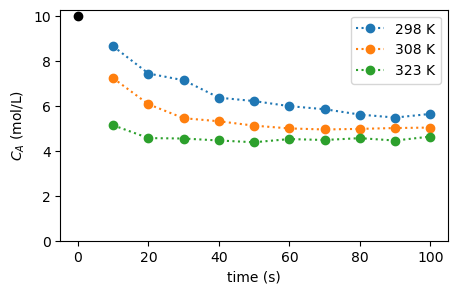

In [25]:
cA0 = 10.0   # mol/L
times = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100.])   # s
cA_data = {   # mol/L, keyed by temperature in K
    298.15: np.array([8.649, 7.441, 7.141, 6.366, 6.215, 5.990, 5.852, 5.615, 5.481, 5.644]),
    308.15: np.array([7.230, 6.073, 5.452, 5.317, 5.121, 4.998, 4.951, 4.978, 5.015, 5.036]),
    323.15: np.array([5.137, 4.568, 4.548, 4.461, 4.382, 4.525, 4.483, 4.565, 4.459, 4.635]),
}
temperatures = np.array(list(cA_data))

for T, cA in cA_data.items():
    plt.plot(times, cA, 'o:', label=f'{T:.0f} K')
plt.plot(0, cA0, 'ko')
plt.xlabel('time (s)')
plt.ylabel('$C_A$ (mol/L)')
plt.ylim(0, None)
plt.legend()
plt.show()

## 1. One temperature

**(a) The model.** Write `cA_model(times, kf, kr)`, which solves the ODE with
`scipy.integrate.solve_ivp` and returns $C_A$ at `times` (use `t_eval`). In Lecture 13 we fitted
functions that were a formula. `curve_fit` doesn't care: any function that takes the
independent variable first and then the parameters, and returns predictions, will do. Even
one that runs a whole simulation.

Then **test it** (Lecture 11). This ODE has an exact solution,
$$C_A(t) = C_{A,\mathrm{eq}} + (C_{A,0} - C_{A,\mathrm{eq}})\,e^{-(k_f+k_r)t},
\qquad C_{A,\mathrm{eq}} = C_{A,0}\frac{k_r}{k_f+k_r}$$
Check that your function agrees with it, for some reasonable $k_f$ and $k_r$, with an
`assert`. (We use `solve_ivp` anyway because your project's model won't have an exact
solution.)

In [26]:
def cA_model(times, kf, kr):
    """C_A (mol/L) at each of `times` (s), for rate constants kf and kr (1/s)."""

    def reactor_ode(t,y):
        cA = y[0]
        return [-kf * cA + kr * (cA0 - cA)]

    solution = scipy.integrate.solve_ivp(reactor_ode, (0, max(times)), [cA0], t_eval=times)

    if not solution.success:
        raise RuntimeError(solution.message)
    
    return solution.y[0]

kf_test = 0.02
kr_test = 0.01

cA_eq = cA0 * kr_test / (kf_test + kr_test)
cA_exact = cA_eq + (cA0 - cA_eq) * np.exp(-(kf_test + kr_test) * times)
cA_numerical = cA_model(times, kf_test, kr_test)

assert np.allclose(cA_numerical, cA_exact, rtol = 1e-3)

print("a")
# your test here

a


**(b) Fit it at 298.15 K**, with `scipy.optimize.curve_fit`. **Try it without `p0` first.**
It may fail with an error from deep inside SciPy, or it may appear to succeed. Either way,
find out what happened: print and plot what came back, or what `cA_model` returns
at `curve_fit`'s default starting point. Then give it a starting guess you can justify
from the data. Roughly how long does $C_A$ take to get halfway to where it ends up?

In [27]:
cA_obs = cA_data[298.15]

try:
    params_default, cov_default = scipy.optimize.curve_fit(cA_model, times, cA_obs)
    print("Default Parameters:", params_default)
    print("Predicted CA:", cA_model(times, *params_default))

except Exception as error:
    print("Fit Failed:", error)
    print("Default Prediction:", cA_model(times, 1, 1))

Default Parameters: [0.5990169  1.08233139]
Predicted CA: [6.44122455 6.44251355 6.44282353 6.44114572 6.43818662 6.43511723
 6.43351637 6.43396531 6.4356017  6.43776434]


In [28]:
guess = [0.02, 0.01]

params_fit, cov_fit = scipy.optimize.curve_fit(cA_model, times, cA_obs, p0 = guess)

kf_fit, kr_fit = params_fit
print("kf =", kf_fit, "1/s")
print("kr =", kr_fit, "1/s")

kf = 0.016788420098606986 1/s
kr = 0.020040253230560315 1/s


In [6]:
# Without the p0, curve_fit returned a kf value of 0.5990 1/s and kr value of 1.08233 1/s. 
# Using these values, it was predicted that the concentration will stay relatively close
# to 6.44 mol/L. This is likely the result of the model reaching equilibrium quickly.
# It reaches halfway at about 20 seconds. The initial guess was [0.02, 0.01] and was
# obtained entirely through AI, and was clearly a great initial guess.

**(c) Look at it.** Plot the data and the fitted curve, and below it the residuals
(data minus model). Report $k_f$ and $k_r$ with their uncertainties.

What happened without `p0`, and why? What starting guess did you use, and how did you
choose it?

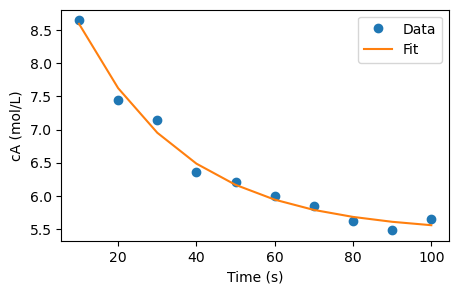

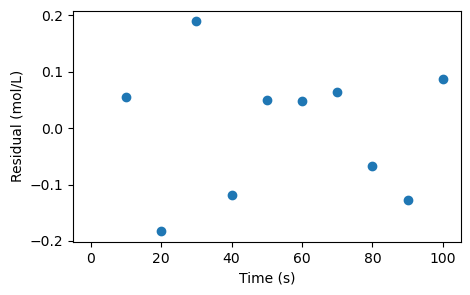

kf = 0.01679 +/- 0.00079 1/s
kr = 0.02004 +/- 0.00154 1/s


In [29]:
cA_fit = cA_model(times, kf_fit, kr_fit)
residuals = cA_obs - cA_fit
errors = np.sqrt(np.diag(cov_fit))

plt.figure()
plt.plot(times, cA_obs, 'o', label = 'Data')
plt.plot(times, cA_fit, '-', label = 'Fit')
plt.xlabel('Time (s)')
plt.ylabel('cA (mol/L)')
plt.legend()
plt.show()

plt.figure()
plt.plot(times, residuals, 'o')
plt.plot(0, color = 'black', linestyle = '--')
plt.xlabel('Time (s)')
plt.ylabel('Residual (mol/L)')
plt.show()

print(f"kf = {kf_fit:.5f} +/- {errors[0]:.5f} 1/s")
print(f"kr = {kr_fit:.5f} +/- {errors[1]:.5f} 1/s")

In [8]:
# The rate constants of the forward and reverse reactions came out to be kf = 0.01679 +/- 0.00079 1/s and 0.02004 +/- 0.00154 1/s, respectively.
# The curve above follows the experimental data closely, and the residuals fluctuate with 0 patterns. The default fit without p0 was far less
# accurate since it approached equilibrium far too quickly.

*Answer:*

## 2. Three temperatures, in two steps

**(a)** Fit $k_f$ and $k_r$ separately at each temperature, and make a small table of
$k_f$, $k_r$ (each with its ±) and $K = k_f/k_r$.

**Before fitting anything else:** from your $K$ values alone, is the reaction endothermic
or exothermic? How can you tell?

In [30]:
results = []

for T, cA in cA_data.items():
    params, cov = scipy.optimize.curve_fit(cA_model, times, cA, p0 = guess)
    kf, kr = params
    errors = np.sqrt(np.diag(cov))
    K = kf / kr
    
    results.append([T, kf, errors[0], kr, errors[1], K])

print("T (K) | kf +/- | kr | kr +/- | K")
for row in results:
    print([round(x, 5) for x in row])

T (K) | kf +/- | kr | kr +/- | K
[298.15, 0.01679, 0.00079, 0.02004, 0.00154, 0.83773]
[308.15, 0.03924, 0.00085, 0.03921, 0.00105, 1.00055]
[323.15, 0.11942, 0.00651, 0.09791, 0.0057, 1.21959]


In [10]:
#  The reaction is endothermic because the equilibrium constant increases with temperature.
#  K increased from 0.83773 to 1.00055, as T, in Kelvin, increases from 298.15 to 308.15.
#  Therefore, higher temperatures favor the forward reaction.

**(b) Arrhenius.** As in Lecture 13: `scipy.stats.linregress` on $\ln k_f$ against
$1/T$ gives $E_a$ from the slope and $\ln A$ from the intercept. Convert $\ln A$ to
$\log_{10} A$.

**(c) van 't Hoff.** Put the two expressions for $\Delta G^\circ$ together and divide by $-RT$:
$$\ln K = -\frac{\Delta H}{R}\,\frac{1}{T} + \frac{\Delta S}{R}$$
So $\ln K$ against $1/T$ is a straight line too, with slope $-\Delta H/R$ and intercept
$\Delta S/R$. Fit it, and get $\Delta H$ and $\Delta S$, with their ±. Does the sign of
$\Delta H$ agree with what you said in (a)?

In [31]:
T = np.array([row[0] for row in results])
kf = np.array([row[1] for row in results])
kr = np.array([row[3] for row in results])

K = kf/kr
fit = scipy.stats.linregress(1/T, np.log(kf))

Ea = -fit.slope * R
Ea_error = fit.stderr * R

A = np.exp(fit.intercept)
logA = fit.intercept / np.log(10)
logA_error = fit.intercept_stderr / np.log(10)

print(f"Ea = {Ea:.2f} +/- {Ea_error:.2f} J/mol")
print(f"log10(A) = {logA:.4f}")
print(f"log10(A) = {logA:.4f} +/- {logA_error:.4f}")

Ea = 62773.67 +/- 951.87 J/mol
log10(A) = 9.2274
log10(A) = 9.2274 +/- 0.1608


In [32]:
fit_K = scipy.stats.linregress(1/T, np.log(K))
dH = -fit_K.slope * R
dS = fit_K.intercept * R
dH_error = fit_K.stderr * R
dS_error = fit_K.intercept_stderr * R

print(f"dH = {dH:.2f} +/- {dH_error:.2f} J/mol")
print(f"dS = {dS:.2f} +/- {dS_error:.2f} J/mol/K")

dH = 11965.25 +/- 736.06 J/mol
dS = 38.72 +/- 2.38 J/mol/K


**(d)** `linregress` gave you a ± on each of these. What does that ± know about,
and what has it left out? Think about how many points each straight line had, and about
the ± you got in (a).

*Answer:* The uncertainties from the lineregress command describe the overall uncertainty in the slope and intercept.
However, they leave out the potential uncertainties of the rate constant, that was brought up in problem 1
The uncertainty was also limited, since only three temperature points were used. Therefore, it only described the 
uncertainty from the linear regression and not the total uncertainty of any of the parameters.

## 3. All the data at once

Step 2 fitted 3 × 2 rate constants, then fitted lines through three points each. Better:
fit the four parameters you actually want **directly to all 30 measurements**, so that
every measurement counts and the uncertainties carry all the way through.

`curve_fit` wants one `xdata` and one `ydata`. With several experiments, stack them:
`ydata` is all 30 concentrations in one array, and `xdata` carries **both** the
temperature and the time of each one. `curve_fit` never looks inside `xdata`; it just passes it
to your function. So it can be a tuple of two arrays:

In [33]:
T_all = np.repeat(temperatures, len(times))     # 298.15 ten times, then 308.15 ten times, ...
t_all = np.tile(times, len(temperatures))        # 10, 20, ..., 100, three times over
cA_all = np.concatenate([cA_data[T] for T in temperatures])
x_all = (T_all, t_all)
print(T_all[:12], t_all[:12], cA_all[:12], sep='\n')

[298.15 298.15 298.15 298.15 298.15 298.15 298.15 298.15 298.15 298.15
 308.15 308.15]
[ 10.  20.  30.  40.  50.  60.  70.  80.  90. 100.  10.  20.]
[8.649 7.441 7.141 6.366 6.215 5.99  5.852 5.615 5.481 5.644 7.23  6.073]


**(a)** Write `cA_model_all(x, log10A, Ea, dH, dS)`. Unpack `x` into temperatures and
times. For each temperature, work out $k_f$, $K$ and $k_r$, then call your `cA_model` for
that temperature's times, and put the results in the right places of the output array.
Solve one ODE per temperature, not one per data point. A boolean mask such as
`T_col == T` picks out the rows.

Notice the **units**: $E_a$ and $\Delta H$ in kJ/mol, $\Delta S$ in J/mol/K, and $A$ as
$\log_{10}A$. That keeps all four parameters between about 1 and 100. An optimizer
has an easier time when its parameters are all a similar size than when one is
$10^{9}$ and another is $10^{-2}$. So convert carefully inside the function.

Then fit it, **starting from your answers to task 2**, and report the four parameters with
their ±.

In [34]:
def cA_model_all(x, log10A, Ea, dH, dS):
    """C_A (mol/L) for every (T, t) pair in x. Ea and dH in kJ/mol, dS in J/mol/K."""
    T_col, t_col = x
    cA_fit = np.zeros(len(t_col))
    
    for T in np.unique(T_col):
        kf = 10**log10A * np.exp(-Ea * 1000 / (R * T))
        K = np.exp(-dH * 1000 / (R * T) + dS / R)
        kr = kf / K
        
        mask = T_col == T
        cA_fit[mask] = cA_model(t_col[mask], kf, kr)

    return cA_fit

In [35]:
guess_another = [logA, Ea / 1000, dH / 1000, dS]

params_another, cov_another = scipy.optimize.curve_fit(cA_model_all, x_all, cA_all, p0 = guess_another)
errors_another = np.sqrt(np.diag(cov_another))

for name, value, error in zip(["log10A", "Ea (kJ/mol)", "dH (kJ/mol)", "dS (J/mol/K)"], params_another, errors_another):
    print(f"{name} = {value:.4f} +/- {error:.4f}")

log10A = 9.4842 +/- 0.3676
Ea (kJ/mol) = 64.2843 +/- 2.1395
dH (kJ/mol) = 11.5257 +/- 0.7897
dS (J/mol/K) = 37.3338 +/- 2.5107


**(b)** Now start from your estimates from before the experiments instead (6, 45, −10, −50).
Does it find the same answer? How far did the data move you from what you expected?

In [36]:
guess_again = [6, 45, -10, -50]
params_again, cov_again = scipy.optimize.curve_fit(cA_model_all, x_all, cA_all, p0 = guess_again, method = "trf", x_scale = [1, 50, 10, 50], max_nfev = 20000)

print("New Fit:", params_again)
print("Previous Fit:", params_another)
print("Difference:", params_again - params_another)

New Fit: [ 9.48419591 64.28421977 11.52572832 37.33380587]
Previous Fit: [ 9.48420166 64.28425334 11.52571425 37.33376092]
Difference: [-5.74994250e-06 -3.35743570e-05  1.40699446e-05  4.49556502e-05]


In [17]:
# Using AI, I came up with another set of initial values, which turned out to be great for this problem
# The fitted parameters to the initial values are shown above in the "New Fit" list. The data across all
# the two lists showed an increase from the initial values. No matter the number chosen in the list,
# the new lists will have a larger value. This indicates the final fit is not dependent on the starting guess.

In [37]:
print("Task 2:", guess_another)
print("Task 3:", params_another)
print("Task 3 Errors:", errors_another)

Task 2: [9.227417398075108, 62.77367090700958, 11.965254783024584, 38.7236526547743]
Task 3: [ 9.48420166 64.28425334 11.52571425 37.33376092]
Task 3 Errors: [0.36755722 2.13950527 0.78967585 2.51065136]


In [19]:
# The parameter estimates of tasks 2 and 3 are not identical, but are somewhat similar. While task 3 uses
# 30 measurements, task 2 first fits rate constants at each temperature and performed a regression on it.
# The error bars are also different, with task 3 uses the measurements directly for error calculation.
# Overall, I would trust task 3 more as it draws its conclusions directly from the measurements themselves.

**(c)** Compare with task 2. Are the centres the same? Are the error bars? Which set of
error bars would you believe, and why?

**(d) The correlation matrix.** The off-diagonal elements of `pcov` say how the errors in
the parameters go together (Lecture 13). Turn the covariance into correlations:
`pcov / np.outer(perr, perr)`. Which pairs are strongly correlated? Why those pairs?
(Think about Lecture 13's ridge, and about the range of temperatures you measured over.)
If someone quotes only your four ± values, what are they missing?

In [38]:
correlation = cov_another / np.outer(errors_another, errors_another)
print(np.round(correlation, 3))

[[ 1.     1.    -0.37  -0.373]
 [ 1.     1.    -0.381 -0.383]
 [-0.37  -0.381  1.     1.   ]
 [-0.373 -0.383  1.     1.   ]]


In [21]:
# The strongest correlation of log10(A) and activation energy (Ea) and a second relationship between the change in enthalpy and entropy.
# This occured because changes in one parameter, causes similar changes in another. Also, the other correlational relationships are negative
# The issue with only quoting four values is that the correlational relationships cannot be properly collected / drawn.

*Answer:*

## 4. Look at the residuals

**Always look at the residuals** (Lecture 13). Plot the residuals of the task 3 fit against
time, one colour per temperature, with a line at zero.

- Do you see a pattern, or does it look like noise?
- Is the scatter about the same width at all three temperatures? Least squares assumed it is.
- Nobody told you the measurement uncertainty, so `curve_fit` (with
  `absolute_sigma=False`, the default) estimated it from the scatter of the residuals.
  Work out that estimate yourself:
  $s = \sqrt{\sum_i r_i^2 / (N - p)}$, with $N$ data points and $p$ parameters. What does
  it say about how precisely $C_A$ was measured?
- Suppose the experimentalist now tells you their instrument is good to ±0.01 mol/L.
  What would that tell you about your model, or about the experiment?

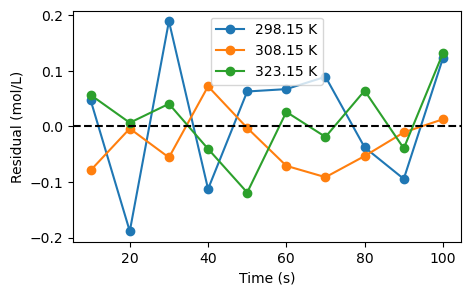

Esitmated Measurement Scatter = 0.08857934456691835 mol/L


In [39]:
cA_fit = cA_model_all(x_all, *params_another)
residuals = cA_all - cA_fit

for T in temperatures:
    mask = T_all == T
    plt.plot(t_all[mask], residuals[mask], 'o-', label = f'{T} K')

plt.axhline(0, color = 'black', linestyle = '--')
plt.xlabel('Time (s)')
plt.ylabel('Residual (mol/L)')
plt.legend()
plt.show()

s = np.sqrt(np.sum(residuals**2) / (len(cA_all) - len(params_another)))
print("Esitmated Measurement Scatter =", s, "mol/L")

In [23]:
# Around zero, the residuals are random; there is no pattern that can be drawn.This shows that the model fits the data well, 
# especially since the scatter data points are quite similar for each temperature. The overall estimated measurement scatter
# 0.88579 mol/L, which is also likely the value of the concentration measurement's uncertainty. If the uncertainty became 0.01
# mol/L, then the residuals would be larger than the -0.2 to 0.2 interval. This likely means there were experimental errors.

*Answer:*

## 5. Your project

One paragraph. Which parameters in your project's model will come from fitting data, and
where will the data come from: your own simulations, the literature, a research group? What
can you say about the errors in those data? Are they the same absolute size, the same
relative size, or known point by point? And are any of your parameters likely to be
correlated, the way $E_a$ and $A$ are here?

*Answer:* My project is lowering the cost of designing catalytic converters, while not affecting the effectiveness of its catalysts.
The parameters that can be come from fitting data are the rate constants and effective affect of catalyst loading. While other values,
such as the diameter and catalyst loading will be varied. Literature will be used for fitting and varying the data. The uncertainty of
literature data can differ, since different experiments likely had different constraints and constants. This means that there is no
absolute error. As for correlation, the reaction rate constant and effective catalyst surface area can be correlated to one another.
This is because they have a proportional relationship: increase one, causes a proportional increase in the other.

## Stretch problems (optional)

**(a) Untangle the ridge.** Write $k_f$ in terms of its value at a reference temperature in
the middle of your data, say $T_\mathrm{ref} = 310$ K:
$$k_f(T) = k_\mathrm{ref}\exp\left[-\frac{E_a}{R}\left(\frac{1}{T} - \frac{1}{T_\mathrm{ref}}\right)\right]$$
It's the same model, written differently. Fit $\log_{10}k_\mathrm{ref}$, $E_a$, $\Delta H$
and $\Delta S$, and look at the correlation matrix again. What changed, and why? Can you do
the same for $\Delta H$ and $\Delta S$?

**(b) Draw the posterior.** At 298.15 K only, put $k_f$ and $k_r$ on a 2-D grid and draw
their posterior, as in Lecture 13, part 5, with a flat prior and Gaussian errors of width
$s$ from task 4. Do its 95% credible intervals (summed over the other parameter) agree with
`curve_fit`'s 95% confidence intervals? Why should they, or why not?

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors, and that the plots
are there. Commit and push. Then check on GitHub that your fork shows your latest commit.